## Data Cleaning 

In [185]:
# import libraries

import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [186]:
# Paths

RAW = pathlib.Path('../data/raw/indian_liver_patient.csv')
PROC = pathlib.Path('../data/processed/liver_cleaned.csv')
OUT = pathlib.Path('../data/outputs')
OUT.mkdir(parents=True, exist_ok=True)

In [187]:
# Load the Liver Patient Dataset as DataFrame

df = pd.read_csv("../data/raw/indian_liver_patient.csv")
df.head(250)

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
245,54,Male,0.9,0.2,290,15,18,6.1,2.8,0.80,1
246,55,Male,1.8,9.0,272,22,79,6.1,2.7,0.70,1
247,55,Male,0.9,0.2,190,25,28,5.9,2.7,0.80,1
248,40,Male,0.7,0.1,202,37,29,5.0,2.6,1.00,1


In [188]:
df.tail(333)

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
250,33,Male,2.1,1.3,480,38,22,6.5,3.0,0.80,1
251,33,Male,0.9,0.8,680,37,40,5.9,2.6,0.80,1
252,65,Male,1.1,0.3,258,48,40,7.0,3.9,1.20,2
253,35,Female,0.6,0.2,180,12,15,5.2,2.7,NaN,2
254,38,Female,0.7,0.1,152,90,21,7.1,4.2,1.40,2
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [189]:
# Shape and Information

print("Shape: ", df.shape)
df.info()

Shape:  (583, 11)
<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    str    
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.2 KB


In [190]:
# Describe the dataset

df.describe(include="all")

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
count,583.000000,583,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
unique,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,441,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,44.746141,NaN,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,NaN,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,NaN,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,NaN,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,NaN,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,NaN,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000


In [191]:
# Find duplicate rows

duplicate_rows = df[df.duplicated(keep=False)]
duplicate_rows

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
18,40,Female,0.9,0.3,293,232,245,6.8,3.1,0.80,1
19,40,Female,0.9,0.3,293,232,245,6.8,3.1,0.80,1
25,34,Male,4.1,2.0,289,875,731,5.0,2.7,1.10,1
26,34,Male,4.1,2.0,289,875,731,5.0,2.7,1.10,1
33,38,Female,2.6,1.2,410,59,57,5.6,3.0,0.80,2
34,38,Female,2.6,1.2,410,59,57,5.6,3.0,0.80,2
54,42,Male,8.9,4.5,272,31,61,5.8,2.0,0.50,1
55,42,Male,8.9,4.5,272,31,61,5.8,2.0,0.50,1
61,58,Male,1.0,0.5,158,37,43,7.2,3.6,1.00,1
62,58,Male,1.0,0.5,158,37,43,7.2,3.6,1.00,1


In [192]:
# Drop duplicate rows

df = df.drop_duplicates()
df[df.duplicated()]

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset


In [193]:
df.shape

(570, 11)

In [194]:
df["Dataset"].value_counts()

Dataset
1    406
2    164
Name: count, dtype: int64

In [195]:
# Find the misssing values

df.isnull().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Dataset                       0
dtype: int64

In [196]:
# Show rows With NULL Values

df[df["Albumin_and_Globulin_Ratio"].isnull()]

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
209,45,Female,0.9,0.3,189,23,33,6.6,3.9,NaN,1
241,51,Male,0.8,0.2,230,24,46,6.5,3.1,NaN,1
253,35,Female,0.6,0.2,180,12,15,5.2,2.7,NaN,2
312,27,Male,1.3,0.6,106,25,54,8.5,4.8,NaN,2


,n_missing,pct
Albumin_and_Globulin_Ratio,4,0.701754


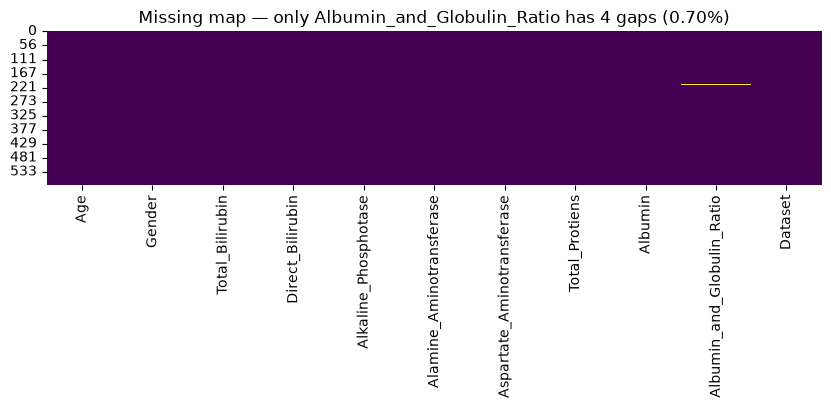

Dataset,1,2
Albumin_and_Globulin_Ratio,,
False,0.995074,0.987805
True,0.004926,0.012195


In [ ]:
# Missing value (NA)
miss = df.isnull().sum().to_frame('n_missing')
miss['pct'] = miss['n_missing']/len(df)*100
display(miss[miss['n_missing']>0])

# Heatmap of NA positions (like Kaggle but annotated)
plt.figure(figsize=(10,2))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing map - only Albumin_and_Globulin_Ratio has 4 gaps (0.-0%)')
plt.show()

# Is missing correlated with target
pd.crosstab(df['Albumin_and_Globulin_Ratio'].isnull(), df['Dataset'], normalize='columns')


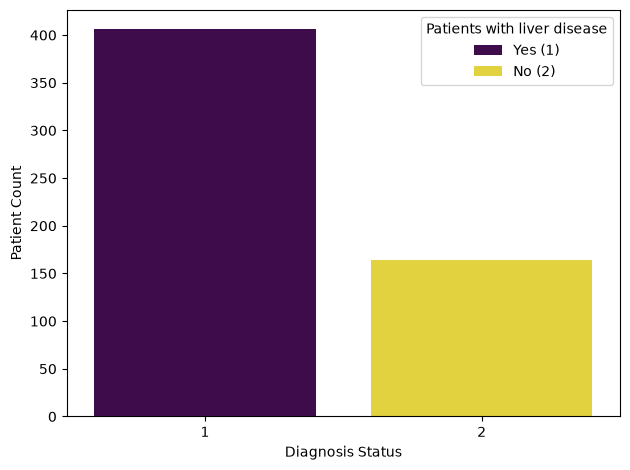

In [198]:
# Visualize "Dataset" Diagnosed with liver disease or not  

ax = sns.countplot(
    data=df, 
    x="Dataset",
    hue="Dataset",
    palette='viridis'
)

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=["Yes (1)", "No (2)"], title="Patients with liver disease")


# ax.set_xticklabels([1, 2])  # Removes the raw '1' and '2' labels from the bottom
ax.set_xlabel("Diagnosis Status")
ax.set_ylabel("Patient Count")

plt.tight_layout()
plt.show()



Female: 75.43859649122807 
Male: 24.561403508771928


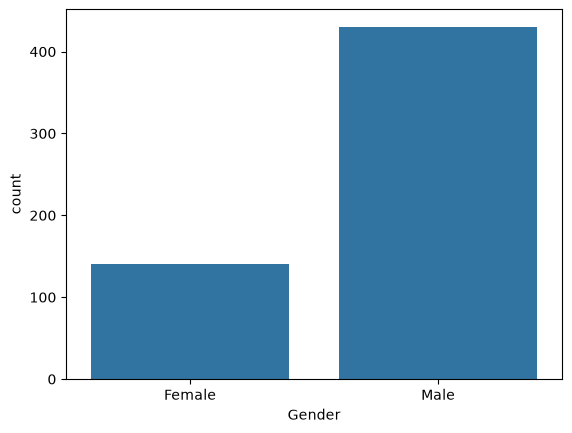

In [199]:
sns.countplot(data=df, x="Gender")

patient_female_percentage, patient_male_percentage = df["Gender"].value_counts(normalize=True) * 100

print("Female:", patient_female_percentage,"\nMale:", patient_male_percentage )

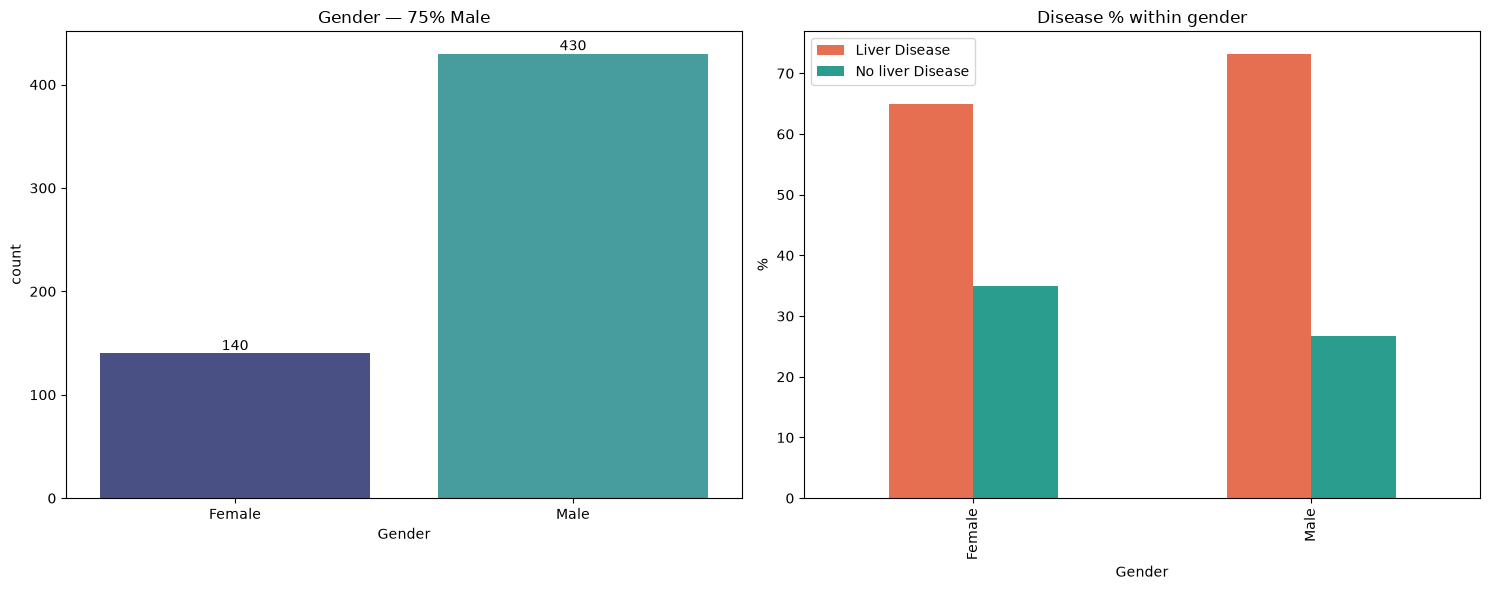

In [200]:
# Check if we have imblance

fig, axes = plt.subplots(1,2, figsize=(15,6))

# Gender overall
sns.countplot(data=df, x='Gender', hue='Gender', palette='mako', legend=False, ax=axes[0])
axes[0].set_title('Gender - 75% Male')
for c in axes[0].containers: axes[0].bar_label(c)

# Gender × Disease 
pd_cros = pd.crosstab(df['Gender'], df['Dataset'], normalize='index')*100
pd_cros.plot(kind='bar', stacked=False, ax=axes[1], color=['#e76f51','#2a9d8f'])
axes[1].set_title('Disease % within gender')
axes[1].set_ylabel('%')
axes[1].legend(['Liver Disease','No liver Disease'])
plt.tight_layout(); 
plt.show()


In [201]:
# Check Imbalance Ratio

display(pd.crosstab(df['Gender'], df['Dataset'], margins=True))
print(f"Imbalance ratio: {df['Dataset'].value_counts(normalize=True).to_dict()}")

print("needs SMOTE in 03 (not here)")


Dataset,1,2,All
Gender,,,
Female,91,49,140
Male,315,115,430
All,406,164,570


Imbalance ratio: {1: 0.712280701754386, 2: 0.28771929824561404}
needs SMOTE in 03 (not here)


In [202]:

print("We might needs SMOTE")


We might needs SMOTE


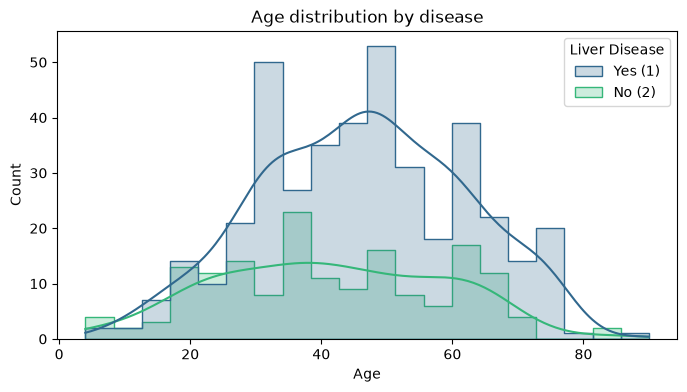

count    570.000000
mean      44.849123
std       16.242182
min        4.000000
25%       33.000000
50%       45.000000
75%       58.000000
max       90.000000
Name: Age, dtype: float64

In [203]:
# Check "Age" Column

plt.figure(figsize=(8,4))
ax = sns.histplot(data=df, x='Age', hue=df['Dataset'].replace({1: "Yes (1)", 2: "No (2)" }), bins=20, palette='viridis', kde=True, element='step')

sns.move_legend(ax, "upper right", title="Liver Disease")
plt.title('Age distribution by disease')
plt.show()
df['Age'].describe()

In [204]:
# Logical check: Direct_Bilirubin should <= Total_Bilirubin

invalid = df[df['Direct_Bilirubin'] > df['Total_Bilirubin']]
print(f"Invalid Direct > Total: {len(invalid)} rows ({len(invalid)/len(df):.1%})")
display(invalid[['Age','Gender','Total_Bilirubin','Direct_Bilirubin','Alkaline_Phosphotase','Dataset']].head())

# No negatives; ranges plausible per describe earlier

Invalid Direct > Total: 3 rows (0.5%)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Dataset
246,55,Male,1.8,9.0,272,1
261,33,Male,1.5,7.0,505,1
279,48,Female,1.0,1.4,144,1


In [205]:
# Age sanity Check
print("Age Min:", df['Age'].min(),"\nAge max:", df['Age'].max())

Age Min: 4 
Age max: 90


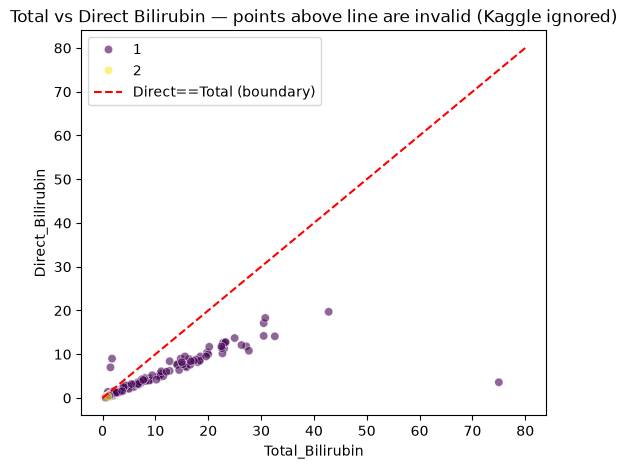

In [206]:
# Visual: scatter Total vs Direct - diagonal = valid

plt.figure(figsize=(6,5))

sns.scatterplot(data=df, x='Total_Bilirubin', y='Direct_Bilirubin', hue='Dataset', palette='viridis', alpha=0.6)
plt.plot([0,80],[0,80],'r--', label='Direct==Total (boundary)')
plt.title('Total vs Direct Bilirubin - points above line are invalid (Kaggle ignored)')
plt.legend(); plt.show()

# We can keep them (real-world noise) but note impact; optionally clip in Pipeline via custom transformer

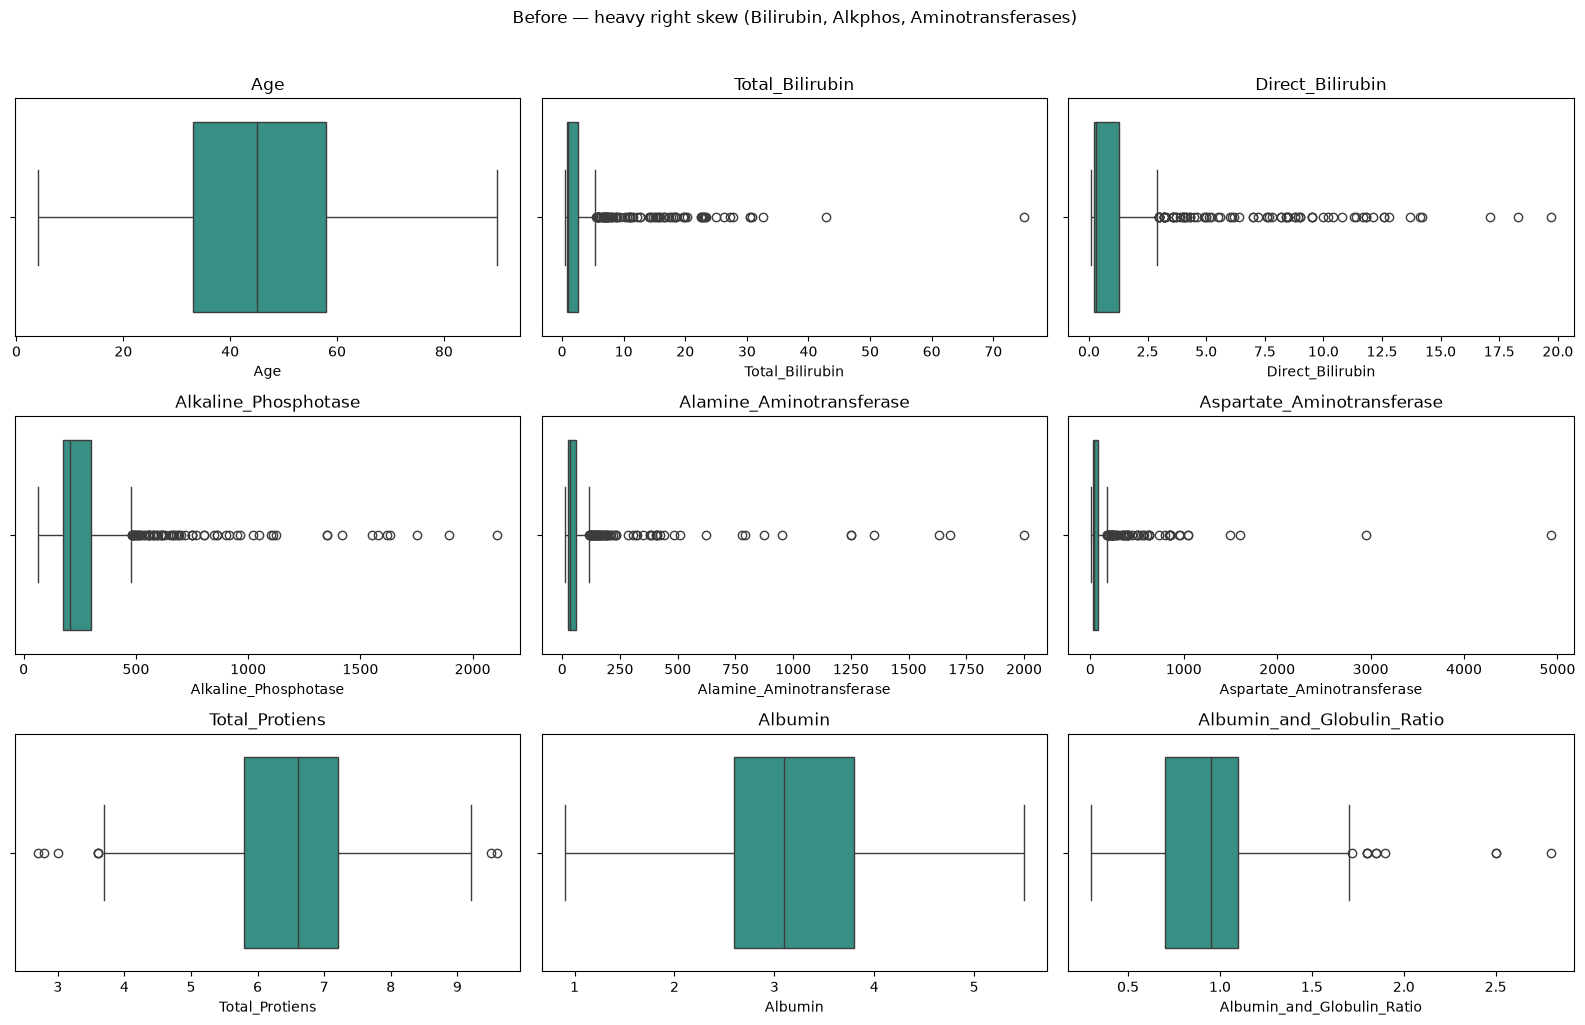

In [207]:
# Check for Outliers

num_cols = ['Age','Total_Bilirubin','Direct_Bilirubin','Alkaline_Phosphotase','Alamine_Aminotransferase','Aspartate_Aminotransferase','Total_Protiens','Albumin','Albumin_and_Globulin_Ratio']

fig, axes = plt.subplots(3,3, figsize=(16,10))

for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax, color='#2a9d8f')
    ax.set_title(col)
plt.suptitle('Before - heavy right skew (Bilirubin, Alkphos, Aminotransferases)', y=1.02)

plt.tight_layout()
plt.show()


In [208]:
# Quantify: what % are beyond 1.5*IQR?
for col in num_cols:
    q1, q3 = df[col].quantile([0.25,0.75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    pct = ((df[col]<lo)|(df[col]>hi)).mean()*100
    print(f"{col:28} Q1={q1:6.1f} Q3={q3:6.1f} IQR={iqr:6.1f}  outliers {pct:4.1f}%  hi={hi:.1f}")

# Decision: Not doing clip here - clip inside Pipeline fitted on train. Save raw for 02_eda

Age                          Q1=  33.0 Q3=  58.0 IQR=  25.0  outliers  0.0%  hi=95.5
Total_Bilirubin              Q1=   0.8 Q3=   2.6 IQR=   1.8  outliers 14.6%  hi=5.3
Direct_Bilirubin             Q1=   0.2 Q3=   1.3 IQR=   1.1  outliers 14.0%  hi=3.0
Alkaline_Phosphotase         Q1= 176.0 Q3= 298.0 IQR= 122.0  outliers 12.1%  hi=481.0
Alamine_Aminotransferase     Q1=  23.0 Q3=  60.0 IQR=  37.0  outliers 12.6%  hi=115.5
Aspartate_Aminotransferase   Q1=  25.0 Q3=  86.8 IQR=  61.8  outliers 11.6%  hi=179.4
Total_Protiens               Q1=   5.8 Q3=   7.2 IQR=   1.4  outliers  1.4%  hi=9.3
Albumin                      Q1=   2.6 Q3=   3.8 IQR=   1.2  outliers  0.0%  hi=5.6
Albumin_and_Globulin_Ratio   Q1=   0.7 Q3=   1.1 IQR=   0.4  outliers  1.8%  hi=1.7


### Correaltions

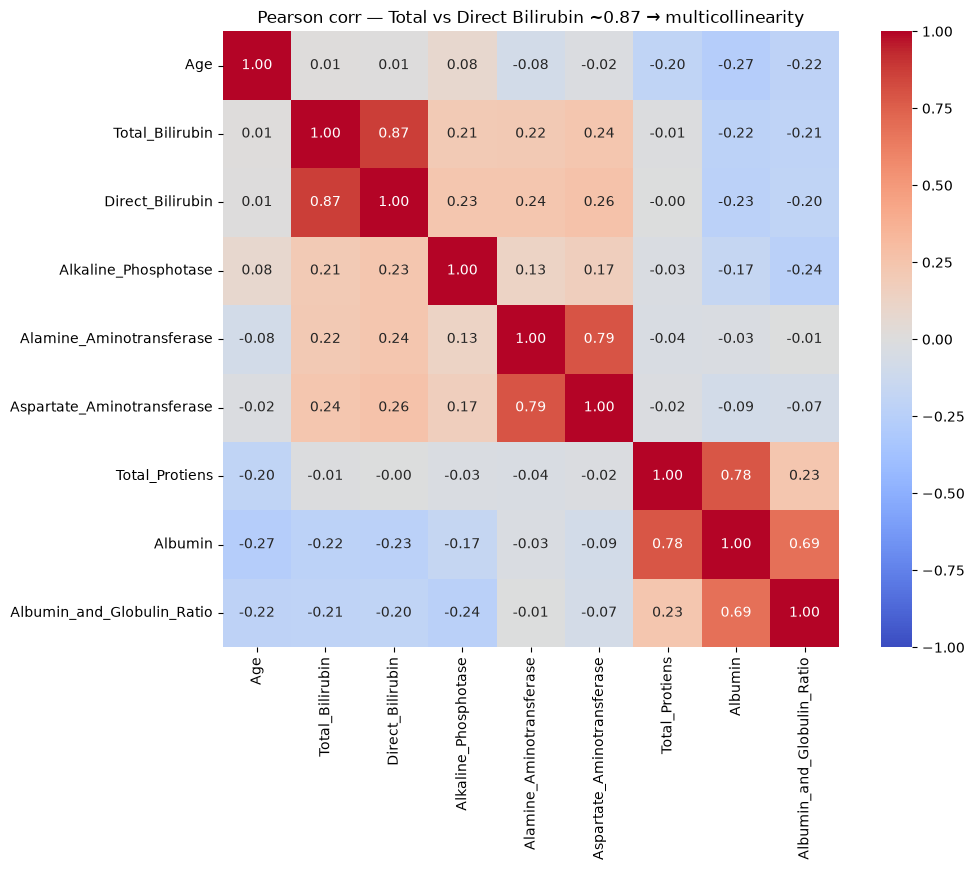

In [209]:
# Pearson corr -"Total" vs "Direct Bilirubin"

plt.figure(figsize=(11,8))
corr = df[num_cols].corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Pearson corr - Total vs Direct Bilirubin ~0.87 → multicollinearity')
plt.show()


In [210]:
# Variance inflation Factor

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = df[num_cols].dropna()
vif = pd.DataFrame({'feature': X_vif.columns, 'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]}).sort_values('VIF', ascending=False)

display(vif)

,feature,VIF
7,Albumin,10.161347
6,Total_Protiens,5.567746
2,Direct_Bilirubin,4.503448
1,Total_Bilirubin,4.257226
8,Albumin_and_Globulin_Ratio,3.696956
4,Alamine_Aminotransferase,2.814969
5,Aspartate_Aminotransferase,2.807532
3,Alkaline_Phosphotase,1.118170
0,Age,1.097965


In [211]:
print('VIF>10 → serious collinearity (Total/Direct). Decision: keep both but Ridge will shrink in 03, or drop one if unstable.')

VIF>10 → serious collinearity (Total/Direct). Decision: keep both but Ridge will shrink in 03, or drop one if unstable.


In [212]:
# Categorical Encoding 

df.dtypes

Age                             int64
Gender                            str
Total_Bilirubin               float64
Direct_Bilirubin              float64
Alkaline_Phosphotase            int64
Alamine_Aminotransferase        int64
Aspartate_Aminotransferase      int64
Total_Protiens                float64
Albumin                       float64
Albumin_and_Globulin_Ratio    float64
Dataset                         int64
dtype: object

In [213]:
df["Gender"].value_counts()

Gender
Male      430
Female    140
Name: count, dtype: int64

In [214]:
# Mapping for reference (not applied now): Male→1, Female→0 if LabelEncoder sorted
# In 03_modles we use OneHotEncoder(drop_first, handle_unknown='ignore') inside Pipeline

In [ ]:
# Save cleaned (deduped only) - NO impute/scale yet
#`SimpleImputer(median)` + `StandardScaler` must fit on train only. We save deduped raw so 02_eda can reload consistently.

PROC.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROC, index=False)
print(f"Saved {PROC} - {PROC.stat().st_size/1024:.1f} KB, shape {df.shape}")
# Verify reload
pd.read_csv(PROC).head(2)

# Also log cleaning summary for outputs/
summary = {
    'raw_shape': [583,11],
    'after_dedup': list(df.shape),
    'duplicates_removed': 13,
    'missing_after_dedup': int(df['Albumin_and_Globulin_Ratio'].isnull().sum()),
    'invalid_direct_gt_total': int((df['Direct_Bilirubin']>df['Total_Bilirubin']).sum()),
    'class_balance': df['Dataset'].value_counts().to_dict(),
    'gender_balance': df['Gender'].value_counts().to_dict(),
}
import json
with open(OUT/'cleaning_summary.json','w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))


Saved ../data/processed/liver_cleaned.csv - 23.0 KB, shape (570, 11)
{
  "raw_shape": [
    583,
    11
  ],
  "after_dedup": [
    570,
    11
  ],
  "duplicates_removed": 13,
  "missing_after_dedup": 4,
  "invalid_direct_gt_total": 3,
  "class_balance": {
    "1": 406,
    "2": 164
  },
  "gender_balance": {
    "Male": 430,
    "Female": 140
  }
}
